<b><font size="10" color="#0a65c7"> Notebook 2 - Client Data Integration and Feature Decisions </font></b><br>

This notebook explores the optional `clientes.csv` table, validates its integration with transaction data and records the client features selected for the first baseline. It does **not** yet split the data, impute values, encode categories or fit a model. Those operations belong in the modelling notebook, where they must be fitted only on the training portion of each split.

**Question:** Do stable client attributes add useful information beyond the transaction and purchase-history data?

<div class="alert alert-block" style="background-color: #abceff; color: #000000;">

<a id="table-of-contents"></a>

## <font color="#0a65c7">Table of Contents</font>

<h3><a href="#2-import-and-explore-the-data" style="color: #0a65c7; text-decoration: none;">2. Client Data Integration</a></h3>

<ul>
  <li style="color: #0a65c7;">
    <a href="#21-imports-and-configuration" style="color: #0a65c7;">2.1 Imports and Configuration</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#22-load-the-official-files" style="color: #0a65c7;">2.2 Load the Official Files</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#23-audit-of-clientescsv" style="color: #0a65c7;">2.3 Audit of `clientes.csv`</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#24-validate-the-merge-key" style="color: #0a65c7;">2.4 Validate the Merge Key</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#25-feature-decisions" style="color: #0a65c7;">2.5 Feature decisions</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#26-safe-integration-of-the-selected-client-features" style="color: #0a65c7;">2.6 Safe Integration of the Selected Client Features</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#27-are-the-core-client-features-associated-with-repeat-purchase" style="color: #0a65c7;">2.7 Are the Core Client Features Associated with Repeat Purchase?</a>
    <ul>
      <li style="color: #0a65c7;">
        <a href="#271-country-or-region" style="color: #0a65c7;">2.7.1 Country or Region</a>
      </li>
      <li style="color: #0a65c7;">
        <a href="#272-commercial-region" style="color: #0a65c7;">2.7.2 Commercial Region</a>
      </li>
      <li style="color: #0a65c7;">
        <a href="#273-island" style="color: #0a65c7;">2.7.3 Island</a>
      </li>
      <li style="color: #0a65c7;">
        <a href="#274-customer-entry-year" style="color: #0a65c7;">2.7.4 Customer-Entry Year</a>
      </li>
    </ul>
  </li>
  <li style="color: #0a65c7;">
    <a href="#28-check-customer_since_year-against-purchase-dates" style="color: #0a65c7;">2.8 Check `customer_since_year` Against Purchase Dates</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#29-cleaning-contract-for-client-enriched-data" style="color: #0a65c7;">2.9 Cleaning Contract for Client-Enriched Data</a>
  </li>
  <li style="color: #0a65c7;">
    <a href="#210-summary" style="color: #0a65c7;">2.10 Summary</a>
  </li>
</ul>

</div>

<a id="2-import-and-explore-the-data"></a>

## <font color="#0a65c7">2. Client Data Integration</font>

<a id="21-imports-and-configuration"></a>

### <font color="#0a65c7">2.1 Imports and Configuration</font>
 
<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')

TARGET = 'repeat_purchase_90d'

# Works whether Jupyter starts in the repository root or in notebooks/.
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / 'data').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / 'data'

if not DATA_DIR.is_dir():
    raise FileNotFoundError('Open this notebook from the repository root or the notebooks directory.')

<a id="22-load-the-official-files"></a>

### <font color="#0a65c7">2.2 Load the Official Files</font>

`train.csv` contains labelled purchase occasions, `test.csv` contains later unlabelled occasions, and `clientes.csv` contains one optional customer-level row per `customer_id`.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [2]:
train = pd.read_csv(DATA_DIR / 'train.csv')
test = pd.read_csv(DATA_DIR / 'test.csv')
clientes = pd.read_csv(DATA_DIR / 'clientes.csv')

print(f'Train: {train.shape[0]:,} rows x {train.shape[1]} columns')
print(f'Test: {test.shape[0]:,} rows x {test.shape[1]} columns')
print(f'Clientes: {clientes.shape[0]:,} rows x {clientes.shape[1]} columns')

display(clientes.head())

Train: 6,534 rows x 39 columns
Test: 986 rows x 38 columns
Clientes: 1,143 rows x 13 columns


,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015


<a id="23-audit-of-clientescsv"></a>

### <font color="#0a65c7">2.3 Audit of `clientes.csv`</font>

Before choosing predictors, we inspect the type, missingness and cardinality of every client column. High-cardinality fields can behave like identifiers: they give a model many sparse categories and can encourage it to memorise customers rather than learn patterns that generalise.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [3]:
client_audit = pd.DataFrame({
    'dtype': clientes.dtypes.astype(str),
    'missing_count': clientes.isna().sum(),
    'missing_pct': clientes.isna().mean() * 100,
    'unique_values': clientes.nunique(dropna=True),
}).reset_index(names='column')

display(client_audit.sort_values('unique_values'))

,column,dtype,missing_count,missing_pct,unique_values
10,customer_type,float64,1143,100.000000,0
3,island,str,578,50.568679,10
1,country_or_region,str,0,0.000000,11
12,customer_since_year,int64,0,0.000000,12
2,commercial_region,str,114,9.973753,37
4,municipality,str,159,13.910761,183
6,postal_area,str,71,6.211724,271
5,city,str,546,47.769029,417
8,street,str,598,52.318460,511
7,postal_code,str,170,14.873141,828


`customer_id` is a key, not a predictor. `company_name` and `address` are almost unique per client, while postal and street fields have many categories. `customer_type` is entirely missing. These fields are documented below but are not part of the first client-enriched baseline.

<a id="24-validate-the-merge-key"></a>

### <font color="#0a65c7">2.4 Validate the Merge Key</font>

The client table must contain one row per customer. Every transaction customer must match a client row, and adding client attributes must not add, remove or reorder purchase occasions.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [4]:
# An assert stops execution if a required check fails.
assert clientes['customer_id'].is_unique, 'clientes.csv must have one row per customer_id.'
assert train['customer_id'].isin(clientes['customer_id']).all(), 'Some train customers do not match clientes.csv.'
assert test['customer_id'].isin(clientes['customer_id']).all(), 'Some test customers do not match clientes.csv.'

print('clientes.csv has one row per customer_id:', clientes['customer_id'].is_unique)
print('All train customers match clientes.csv:', train['customer_id'].isin(clientes['customer_id']).all())
print('All test customers match clientes.csv:', test['customer_id'].isin(clientes['customer_id']).all())

clientes.csv has one row per customer_id: True
All train customers match clientes.csv: True
All test customers match clientes.csv: True


<a id="25-feature-decisions"></a>

### <font color="#0a65c7">2.5 Feature decisions</font>

We use a conservative first set of client features. The table records every column in `clientes.csv`, including variables deliberately excluded or deferred for a later experiment.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [5]:
client_feature_decisions = pd.DataFrame(
    [
        ['customer_id', 'Merge key only', 'Identifier used to join tables; never a predictor.'],
        ['country_or_region', 'Include in core baseline', 'Broad geography; 11 categories and no missing values.'],
        ['commercial_region', 'Include in core baseline', 'Commercial segmentation; target rates differ across sufficiently represented regions.'],
        ['island', 'Include in core baseline', 'Geographic grouping; missingness may identify a meaningful group.'],
        ['municipality', 'Defer', '183 client categories; useful to test later, but too granular for the first baseline.'],
        ['city', 'Exclude', '417 client categories and substantial missingness.'],
        ['postal_area', 'Defer', '271 client categories; more granular geography can be tested later.'],
        ['postal_code', 'Exclude', '828 client categories; almost identifier-like.'],
        ['street', 'Exclude', '511 categories and more than half of client rows are missing.'],
        ['address', 'Exclude', '1,120 unique values for 1,143 clients; effectively an identifier.'],
        ['customer_type', 'Exclude', '100% missing.'],
        ['company_name', 'Exclude', '1,141 unique values for 1,143 clients; effectively an identifier.'],
        ['customer_since_year', 'Include in core baseline as a category', 'Customer-entry cohort; its relationship with repeat purchase is not assumed to be linear.'],
    ],
    columns=['client column', 'decision', 'reason'],
)

display(
    client_feature_decisions.style.set_properties(
        subset=['reason'],
        **{'white-space': 'normal', 'width': '420px', 'max-width': '420px'}
    )
)

,client column,decision,reason
0,customer_id,Merge key only,Identifier used to join tables; never a predictor.
1,country_or_region,Include in core baseline,Broad geography; 11 categories and no missing values.
2,commercial_region,Include in core baseline,Commercial segmentation; target rates differ across sufficiently represented regions.
3,island,Include in core baseline,Geographic grouping; missingness may identify a meaningful group.
4,municipality,Defer,"183 client categories; useful to test later, but too granular for the first baseline."
5,city,Exclude,417 client categories and substantial missingness.
6,postal_area,Defer,271 client categories; more granular geography can be tested later.
7,postal_code,Exclude,828 client categories; almost identifier-like.
8,street,Exclude,511 categories and more than half of client rows are missing.
9,address,Exclude,"1,120 unique values for 1,143 clients; effectively an identifier."


The first client-enriched baseline will use only four attributes:

```text
country_or_region
commercial_region
island
customer_since_year
```

`customer_since_year` is stored as a number but will be treated as a category in the model. A client entering in 2017 is not assumed to have an effect that is exactly one unit away from a client entering in 2018.

<a id="26-safe-integration-of-the-selected-client-features"></a>

### <font color="#0a65c7">2.6 Safe Integration of the Selected Client Features</font>

The merge is performed in memory. The raw CSVs are never changed. We join only the four selected features and verify that row counts and row order are preserved.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [6]:
CLIENT_FEATURES_CORE = [
    'country_or_region',
    'commercial_region',
    'island',
    'customer_since_year',
]
CLIENT_JOIN_COLUMNS = ['customer_id'] + CLIENT_FEATURES_CORE

# left: keep every purchase; many_to_one: one client row per customer_id.
train_with_clients = train.merge(
    clientes[CLIENT_JOIN_COLUMNS],
    on='customer_id',
    how='left',
    validate='many_to_one',
    sort=False,
)
test_with_clients = test.merge(
    clientes[CLIENT_JOIN_COLUMNS],
    on='customer_id',
    how='left',
    validate='many_to_one',
    sort=False,
)

assert len(train_with_clients) == len(train), 'The train merge changed the number of rows.'
assert len(test_with_clients) == len(test), 'The test merge changed the number of rows.'
assert train_with_clients['ID'].equals(train['ID']), 'The train merge changed row order.'
assert test_with_clients['ID'].equals(test['ID']), 'The test merge changed row order.'

print('Safe merge confirmed.')
print(f'Train rows before/after merge: {len(train):,} / {len(train_with_clients):,}')
print(f'Test rows before/after merge: {len(test):,} / {len(test_with_clients):,}')
display(train_with_clients[CLIENT_JOIN_COLUMNS + [TARGET]].head())

Safe merge confirmed.
Train rows before/after merge: 6,534 / 6,534
Test rows before/after merge: 986 / 986


,customer_id,country_or_region,commercial_region,island,customer_since_year,repeat_purchase_90d
0,660784,Country CT10: Land of The Final Version,Region RG25: We Will See Later,NaN,2024,1
1,189146,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS8: The Pivot Archipelago,2015,1
2,103940,Country CT10: Land of The Final Version,Region RG23: We Will See Later,NaN,2017,1
3,512927,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS7: The Pivot Archipelago,2018,0
4,122356,Country CT10: Land of The Final Version,Region RG31: We Will See Later,NaN,2017,1


<a id="27-are-the-core-client-features-associated-with-repeat-purchase"></a>

### <font color="#0a65c7">2.7 Are the Core Client Features Associated with Repeat Purchase?</font>

Tables and plots compare repeat-purchase rates (%) for categories with at least 30 purchases. This display threshold avoids focusing on very small groups; it is not a cleaning rule or a guarantee of reliable estimates. The number of omitted categories and purchases is reported below each table.

Short codes such as CT10, RG17 and IS8 identify the original categories. All categories remain in the data. The dashed line shows the overall repeat-purchase rate. Only two countries meet the display threshold.

<a id="271-country-or-region"></a>

#### <font color="#0a65c7">2.7.1 Country or Region</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

,Purchases,Repeat purchase (%)
Category,,
CT10,6321,56.5
CT5,194,39.2


Categories with fewer than 30 purchases omitted from display: 5
Purchases in these categories: 19


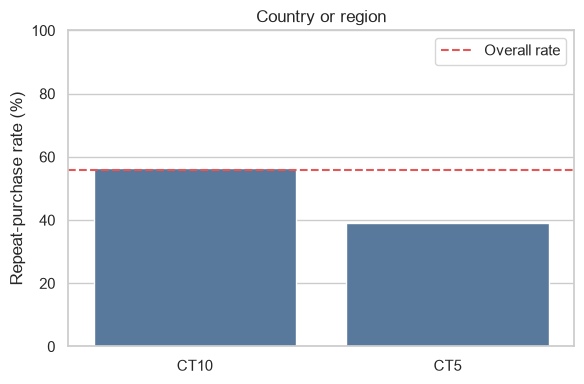

In [7]:
feature = 'country_or_region'
overall_repeat_rate = train_with_clients[TARGET].mean()

# This copy is only for exploration; the merged data stay unchanged.
feature_data = train_with_clients[[feature, TARGET]].copy()
feature_data[feature] = feature_data[feature].fillna('Missing')

# For a 0/1 target, the mean is the proportion of repeat purchases.
feature_rates = feature_data.groupby(feature)[TARGET].agg(['count', 'mean'])
feature_rates.columns = ['purchases', 'repeat_purchase_rate']
feature_rates = feature_rates.sort_values('purchases', ascending=False)

# Show the same categories in the table and plot.
plot_rates = feature_rates[feature_rates['purchases'] >= 30].reset_index()

# Short labels are only used for display.
plot_rates['label'] = plot_rates[feature].str.split(':').str[0]
plot_rates['label'] = plot_rates['label'].str.replace('Country ', '', regex=False)
plot_rates['repeat_purchase_pct'] = plot_rates['repeat_purchase_rate'] * 100

# Compact table: category, sample size and percentage.
rate_table = plot_rates[['label', 'purchases', 'repeat_purchase_pct']].copy()
rate_table.columns = ['Category', 'Purchases', 'Repeat purchase (%)']
display(rate_table.set_index('Category').round(1))

small_groups = feature_rates[feature_rates['purchases'] < 30]
print('Categories with fewer than 30 purchases omitted from display:', len(small_groups))
print('Purchases in these categories:', small_groups['purchases'].sum())

plt.figure(figsize=(6, 4))
sns.barplot(data=plot_rates, x='label', y='repeat_purchase_pct', color='#4C78A8')
plt.axhline(overall_repeat_rate * 100, color='#E45756', linestyle='--', label='Overall rate')
plt.title('Country or region')
plt.xlabel('')
plt.ylabel('Repeat-purchase rate (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

<a id="272-commercial-region"></a>

#### <font color="#0a65c7">2.7.2 Commercial Region</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

,Purchases,Repeat purchase (%)
Category,,
RG17,4109,51.9
RG23,564,82.4
RG18,368,62.0
RG24,235,94.5
RG29,214,50.5
RG27,194,64.9
RG31,165,46.1
RG28,120,44.2
RG9,119,44.5


Categories with fewer than 30 purchases omitted from display: 16
Purchases in these categories: 75


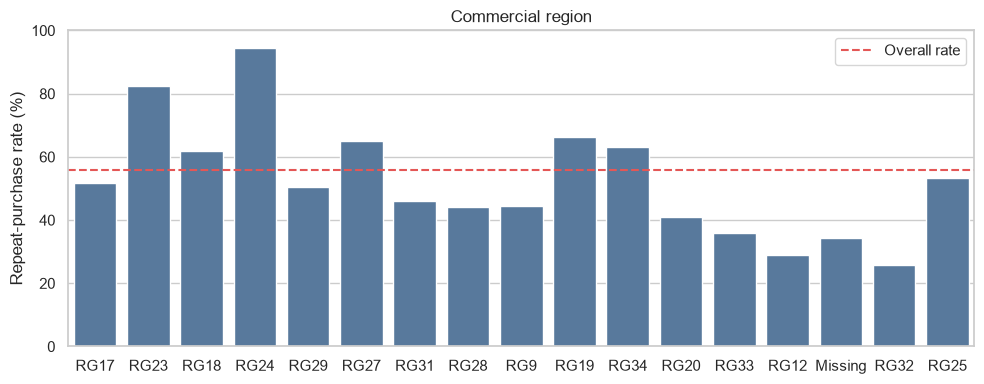

In [8]:
feature = 'commercial_region'
overall_repeat_rate = train_with_clients[TARGET].mean()

# This copy is only for exploration; the merged data stay unchanged.
feature_data = train_with_clients[[feature, TARGET]].copy()
feature_data[feature] = feature_data[feature].fillna('Missing')

# For a 0/1 target, the mean is the proportion of repeat purchases.
feature_rates = feature_data.groupby(feature)[TARGET].agg(['count', 'mean'])
feature_rates.columns = ['purchases', 'repeat_purchase_rate']
feature_rates = feature_rates.sort_values('purchases', ascending=False)

# Show the same categories in the table and plot.
plot_rates = feature_rates[feature_rates['purchases'] >= 30].reset_index()

# Short labels are only used for display.
plot_rates['label'] = plot_rates[feature].str.split(':').str[0]
plot_rates['label'] = plot_rates['label'].str.replace('Region ', '', regex=False)
plot_rates['repeat_purchase_pct'] = plot_rates['repeat_purchase_rate'] * 100

# Compact table: category, sample size and percentage.
rate_table = plot_rates[['label', 'purchases', 'repeat_purchase_pct']].copy()
rate_table.columns = ['Category', 'Purchases', 'Repeat purchase (%)']
display(rate_table.set_index('Category').round(1))

small_groups = feature_rates[feature_rates['purchases'] < 30]
print('Categories with fewer than 30 purchases omitted from display:', len(small_groups))
print('Purchases in these categories:', small_groups['purchases'].sum())

plt.figure(figsize=(10, 4))
sns.barplot(data=plot_rates, x='label', y='repeat_purchase_pct', color='#4C78A8')
plt.axhline(overall_repeat_rate * 100, color='#E45756', linestyle='--', label='Overall rate')
plt.title('Commercial region')
plt.xlabel('')
plt.ylabel('Repeat-purchase rate (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

<a id="273-island"></a>

#### <font color="#0a65c7">2.7.3 Island</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

,Purchases,Repeat purchase (%)
Category,,
Missing,2211,64.0
IS8,839,52.9
IS7,829,49.8
IS4,629,57.1
IS6,564,52.5
IS5,506,51.8
IS1,375,42.4
IS3,260,62.7
IS9,204,51.5


Categories with fewer than 30 purchases omitted from display: 1
Purchases in these categories: 10


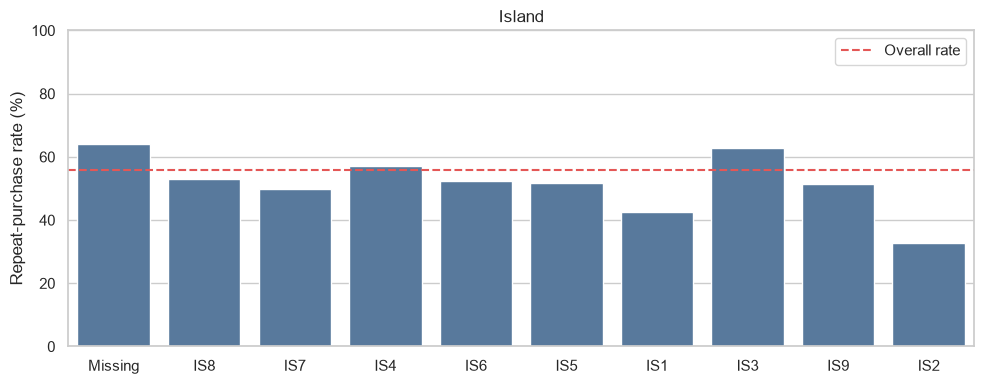

In [9]:
feature = 'island'
overall_repeat_rate = train_with_clients[TARGET].mean()

# This copy is only for exploration; the merged data stay unchanged.
feature_data = train_with_clients[[feature, TARGET]].copy()
feature_data[feature] = feature_data[feature].fillna('Missing')

# For a 0/1 target, the mean is the proportion of repeat purchases.
feature_rates = feature_data.groupby(feature)[TARGET].agg(['count', 'mean'])
feature_rates.columns = ['purchases', 'repeat_purchase_rate']
feature_rates = feature_rates.sort_values('purchases', ascending=False)

# Show the same categories in the table and plot.
plot_rates = feature_rates[feature_rates['purchases'] >= 30].reset_index()

# Short labels are only used for display.
plot_rates['label'] = plot_rates[feature].str.split(':').str[0]
plot_rates['label'] = plot_rates['label'].str.replace('Island ', '', regex=False)
plot_rates['repeat_purchase_pct'] = plot_rates['repeat_purchase_rate'] * 100

# Compact table: category, sample size and percentage.
rate_table = plot_rates[['label', 'purchases', 'repeat_purchase_pct']].copy()
rate_table.columns = ['Category', 'Purchases', 'Repeat purchase (%)']
display(rate_table.set_index('Category').round(1))

small_groups = feature_rates[feature_rates['purchases'] < 30]
print('Categories with fewer than 30 purchases omitted from display:', len(small_groups))
print('Purchases in these categories:', small_groups['purchases'].sum())

plt.figure(figsize=(10, 4))
sns.barplot(data=plot_rates, x='label', y='repeat_purchase_pct', color='#4C78A8')
plt.axhline(overall_repeat_rate * 100, color='#E45756', linestyle='--', label='Overall rate')
plt.title('Island')
plt.xlabel('')
plt.ylabel('Repeat-purchase rate (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

<a id="274-customer-entry-year"></a>

#### <font color="#0a65c7">2.7.4 Customer-Entry Year</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

,Purchases,Repeat purchase (%)
Category,,
2015,3573,59.5
2016,605,56.7
2017,885,66.8
2018,467,34.9
2019,278,42.8
2020,273,49.1
2021,208,36.5
2022,111,25.2
2023,108,60.2


Categories with fewer than 30 purchases omitted from display: 1
Purchases in these categories: 26


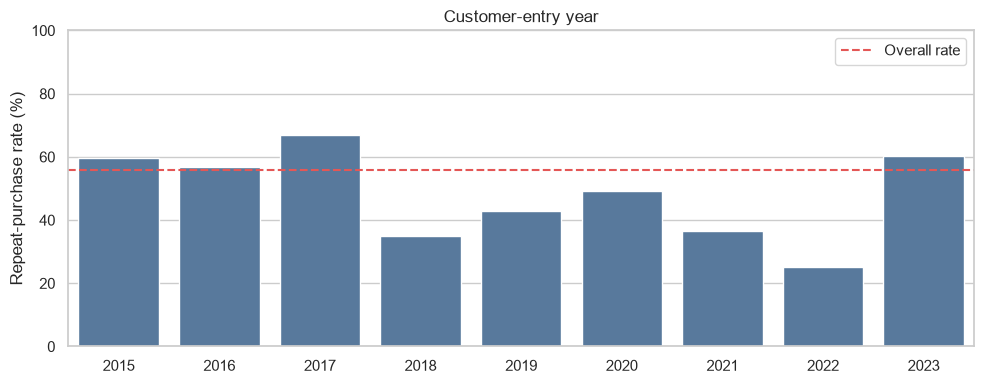

In [10]:
feature = 'customer_since_year'
overall_repeat_rate = train_with_clients[TARGET].mean()

# This copy is only for exploration; the merged data stay unchanged.
feature_data = train_with_clients[[feature, TARGET]].copy()
feature_data[feature] = feature_data[feature].fillna('Missing')

# For a 0/1 target, the mean is the proportion of repeat purchases.
feature_rates = feature_data.groupby(feature)[TARGET].agg(['count', 'mean'])
feature_rates.columns = ['purchases', 'repeat_purchase_rate']
feature_rates = feature_rates.sort_values('purchases', ascending=False)

# Show the same categories in the table and plot.
plot_rates = feature_rates[feature_rates['purchases'] >= 30].reset_index()

# Short labels are only used for display.
plot_rates = plot_rates.sort_values(feature)
plot_rates['label'] = plot_rates[feature].astype(str)
plot_rates['repeat_purchase_pct'] = plot_rates['repeat_purchase_rate'] * 100

# Compact table: category, sample size and percentage.
rate_table = plot_rates[['label', 'purchases', 'repeat_purchase_pct']].copy()
rate_table.columns = ['Category', 'Purchases', 'Repeat purchase (%)']
display(rate_table.set_index('Category').round(1))

small_groups = feature_rates[feature_rates['purchases'] < 30]
print('Categories with fewer than 30 purchases omitted from display:', len(small_groups))
print('Purchases in these categories:', small_groups['purchases'].sum())

plt.figure(figsize=(10, 4))
sns.barplot(data=plot_rates, x='label', y='repeat_purchase_pct', color='#4C78A8')
plt.axhline(overall_repeat_rate * 100, color='#E45756', linestyle='--', label='Overall rate')
plt.title('Customer-entry year')
plt.xlabel('')
plt.ylabel('Repeat-purchase rate (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

The plots show meaningful variation in repeat-purchase rates for `commercial_region`, `island` and `customer_since_year`. Missing `island` is itself a large group with a distinct rate, so it should be represented explicitly rather than dropping the column. These patterns justify testing the four selected features, but they are not proof of future predictive value: the temporal validation experiment will make that decision.

<a id="28-check-customer_since_year-against-purchase-dates"></a>

### <font color="#0a65c7">2.8 Check `customer_since_year` Against Purchase Dates</font>

Customer-entry year must not come after the purchase being described. We check this on both the labelled and unlabelled transaction files.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [11]:
for name, frame in [('train', train_with_clients), ('test', test_with_clients)]:
    purchase_year = pd.to_datetime(frame['purchase_date'], errors='coerce').dt.year
    future_entry_year = frame['customer_since_year'] > purchase_year
    print(f'{name}: customer_since_year after purchase year = {future_entry_year.sum()}')

train: customer_since_year after purchase year = 0
test: customer_since_year after purchase year = 0


For purchases with a valid date, no client-entry year is later than the purchase year. This supports date consistency, but does not prove that the supplied client attributes were available at the time of each purchase. Their historical availability remains an assumption for the modelling experiments.

<a id="29-cleaning-contract-for-client-enriched-data"></a>

### <font color="#0a65c7">2.9 Cleaning Contract for Client-Enriched Data</font>

The revised transaction rules from Notebook 01 also apply after client enrichment: reconstruct historical values when an audited same-row identity determines them exactly; otherwise leave invalid values missing for fold-fitted imputation. The same 65 undated, almost-empty purchases are excluded from both modelling experiments. IDs remain join/submission keys, not predictors. The table below adds only client-specific rules.

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

In [12]:
client_cleaning_contract = pd.DataFrame(
    [
        ['customer_id', 'Use only to join the files; do not use in the model', 'Identifier.'],
        ['country_or_region', 'Keep as categorical; no missing-value action', 'No missing or blank values.'],
        ['commercial_region', 'Fill missing with the category Missing inside each training fold', '114 client records are missing this field.'],
        ['island', 'Fill missing with the category Missing inside each training fold', 'Missing values have a different observed repeat-purchase rate; they do not necessarily mean mainland.'],
        ['customer_since_year', 'Treat as categorical and one-hot encode inside each training fold', 'Each entry year may have a different effect; no values are missing.'],
        ['municipality / postal_area', 'Test later; do not use in the first model', 'Many geographic categories; test their usefulness in a later experiment.'],
        ['city / postal_code / street', 'Do not use in the model', 'Very specific locations; many categories have few observations.'],
        ['address / company_name', 'Do not use in the model', 'Values are almost unique per client; the model could memorise clients.'],
        ['customer_type', 'Do not use in the model', 'All values are missing.'],
    ],
    columns=['item', 'proposed rule', 'reason'],
)

# Show complete sentences, with line wrapping and left alignment.
display(
    client_cleaning_contract.style.set_properties(
        **{'white-space': 'normal', 'max-width': '350px', 'text-align': 'left'}
    )
)

,item,proposed rule,reason
0,customer_id,Use only to join the files; do not use in the model,Identifier.
1,country_or_region,Keep as categorical; no missing-value action,No missing or blank values.
2,commercial_region,Fill missing with the category Missing inside each training fold,114 client records are missing this field.
3,island,Fill missing with the category Missing inside each training fold,Missing values have a different observed repeat-purchase rate; they do not necessarily mean mainland.
4,customer_since_year,Treat as categorical and one-hot encode inside each training fold,Each entry year may have a different effect; no values are missing.
5,municipality / postal_area,Test later; do not use in the first model,Many geographic categories; test their usefulness in a later experiment.
6,city / postal_code / street,Do not use in the model,Very specific locations; many categories have few observations.
7,address / company_name,Do not use in the model,Values are almost unique per client; the model could memorise clients.
8,customer_type,Do not use in the model,All values are missing.


<a id="210-summary"></a>

### <font color="#0a65c7">2.10 Summary</font>

<a href="#table-of-contents" style="color: #a9a9a9; font-size: 13px; text-decoration: none;">&#8593; Back to TOC</a>

Each customer can have several purchases. The merge preserves every transaction row and adds four client attributes: country/region, commercial region, island and customer-entry year. The transaction cleaning rules from Notebook 01 still apply.

The modelling notebook will compare transaction-only and client-enriched data using the same temporal split with a 90-day gap. Imputation, one-hot encoding, scaling and the logistic-regression model will be fitted only on the training partition of each experiment.